In [1]:
#DMV-5 : AQI - Analyzing Air Quality Index (AQI) Trends in a City

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load dataset
url = "https://raw.githubusercontent.com/adityarc19/aqi-india/refs/heads/main/city_day.csv"
df = pd.read_csv(url)

In [3]:
# Explore dataset
print(df.head())
print(df.info())

        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  ----- 

In [4]:
df = df[df["City"] == "Mumbai"].copy()

In [5]:
# Handle missing values
df = df.dropna(subset=["AQI", "PM2.5", "PM10", "CO"])

# Convert date column
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

# Extract year
df["Year"] = df["Date"].dt.year

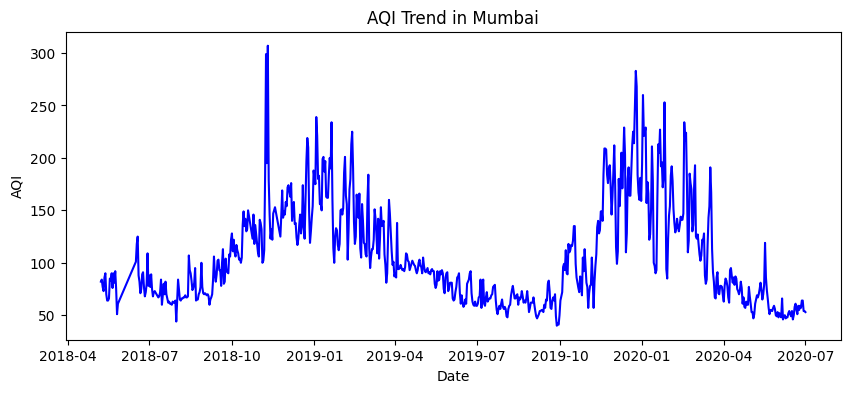

In [6]:
# Line plot - AQI trend
plt.figure(figsize=(10, 4))
plt.plot(df["Date"], df["AQI"], color="blue")
plt.title("AQI Trend in Mumbai")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.show()

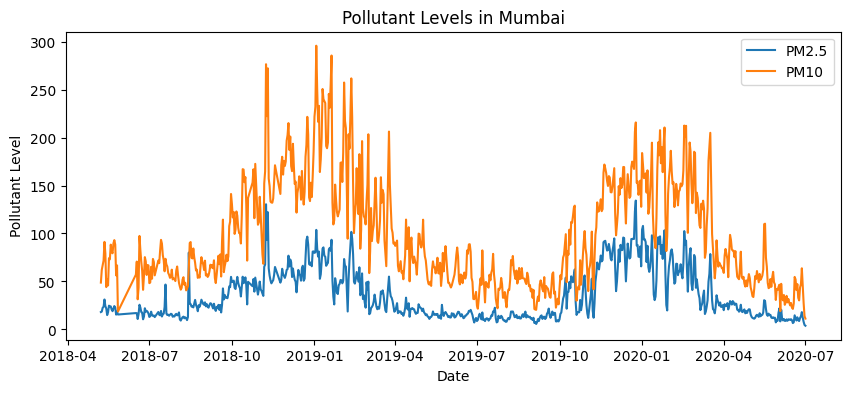

In [7]:
# Line plot - Pollutant levels
plt.figure(figsize=(10, 4))
plt.plot(df["Date"], df["PM2.5"], label="PM2.5")
plt.plot(df["Date"], df["PM10"], label="PM10")
plt.title("Pollutant Levels in Mumbai")
plt.xlabel("Date")
plt.ylabel("Pollutant Level")
plt.legend()
plt.show()

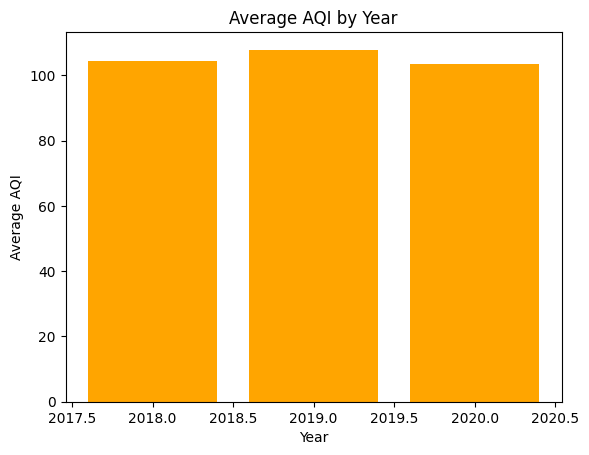

In [8]:
# Bar plot - Average AQI by year
yearly_aqi = df.groupby("Year")["AQI"].mean()

plt.bar(yearly_aqi.index, yearly_aqi.values, color="orange")
plt.title("Average AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.show()

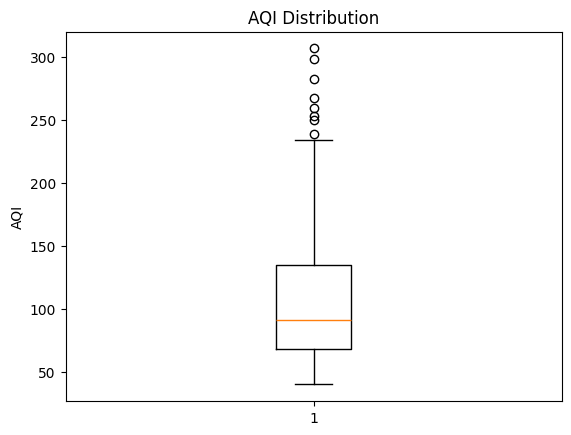

In [9]:
# Box plot - AQI distribution
plt.boxplot(df["AQI"].dropna())
plt.title("AQI Distribution")
plt.ylabel("AQI")
plt.show()

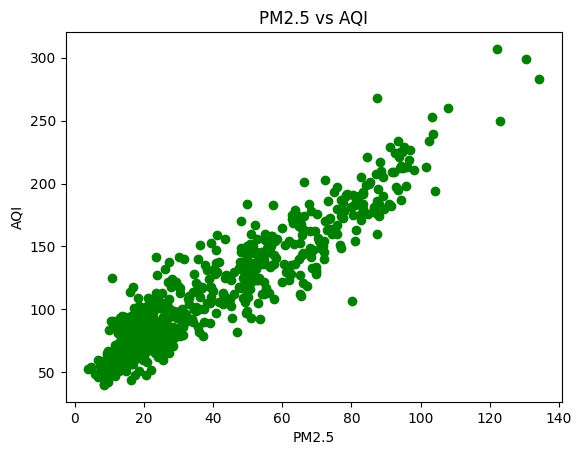

AQI Visualization Completed Successfully!


In [10]:
# Scatter plot - PM2.5 vs AQI
plt.scatter(df["PM2.5"], df["AQI"], color="green")
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.show()

print("AQI Visualization Completed Successfully!")